# 05 · Evaluación y comparación de modelos

Compara la regresión logística (`pipeline/train_logistic.py`) y la red neuronal
(`pipeline/train_neural.py`) sobre **el mismo conjunto de prueba** (1.409 clientes que ningún modelo vio).
El test solo se usa para reportar: umbrales y arquitecturas se eligen con datos de entrenamiento.

1. Capacidad de ordenar por riesgo (AUC) y sobreajuste (brecha entrenamiento → prueba).
2. Del modelo a la decisión: umbral de contacto según costos de Telco (FN = USD 120, FP = USD 15).
3. ¿La diferencia entre modelos es real? Bootstrap pareado.
4. ¿Por qué la red no supera a la logística? Arquitecturas, interacciones y un segmento difícil.

Salidas: `ml/reports/tables/{churn_threshold_comparison,bootstrap_lr_vs_nn,arquitecturas,arquitecturas_resumen}.csv`,
`ml/reports/figures/modelos/*.png`

In [1]:
import sys

sys.path.insert(0, "..")

import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import joblib
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, log_loss,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from pipeline.train_neural import build_model, fit, predict
from telco import paths, style
from telco.data import (FALSE_NEGATIVE_COST, FALSE_POSITIVE_COST, NUMERIC, SEED, features, load_clean, split,
                        split_validation)
from telco.style import CHURN, LABELS, MUTED, STAY

style.apply()
tf.config.experimental.enable_op_determinism()
pd.set_option("display.width", 220)

X, y = features(load_clean())
X_dev, X_test, y_dev, y_test = split(X, y)
X_train, X_val, y_train, y_val = split_validation(X_dev, y_dev)   # solo la red usa validación
logistic = joblib.load(paths.LOGISTIC_MODEL)
neural = keras.models.load_model(paths.NEURAL_MODEL)
p_test = {"logistic": logistic.predict_proba(X_test)[:, 1], "neural": predict(neural, X_test)}
NAME = {"logistic": "Regresión logística", "neural": "Red neuronal"}
print(f"Desarrollo {len(X_dev):,} (red: entrenamiento {len(X_train):,} + validación {len(X_val):,}) · "
      f"prueba {len(X_test):,} con {int(y_test.sum())} abandonos")

I0000 00:00:1795102038.749145  983274 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795102038.749466  983274 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795102039.854660  983274 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795102039.854889  983274 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Desarrollo 5,634 (red: entrenamiento 4,507 + validación 1,127) · prueba 1,409 con 374 abandonos


## 1. Capacidad de ordenar por riesgo y sobreajuste
AUC-ROC y AUC precisión-recall no dependen de un umbral. La brecha entre entrenamiento y prueba
mide memorización: la red pierde más al pasar a datos nuevos.

In [2]:
p_fit = {"logistic": (logistic.predict_proba(X_dev)[:, 1], y_dev), "neural": (predict(neural, X_train), y_train)}
summary = pd.DataFrame({
    NAME[m]: {
        "parámetros": int(logistic.named_steps["logreg"].coef_.size + 1) if m == "logistic"
        else int(sum(np.prod(w.shape) for w in neural.trainable_weights)),
        "AUC entrenamiento": roc_auc_score(p_fit[m][1], p_fit[m][0]),
        "AUC prueba": roc_auc_score(y_test, p_test[m]),
        "AUC-PR prueba": average_precision_score(y_test, p_test[m]),
        "log-loss entrenamiento": log_loss(p_fit[m][1], p_fit[m][0]),
        "log-loss prueba": log_loss(y_test, p_test[m]),
        "Brier prueba": brier_score_loss(y_test, p_test[m]),
    } for m in NAME
})
summary.loc["brecha AUC"] = summary.loc["AUC entrenamiento"] - summary.loc["AUC prueba"]
summary.round(4)

,Regresión logística,Red neuronal
parámetros,26.0000,1377.0000
AUC entrenamiento,0.8492,0.8594
AUC prueba,0.8425,0.8361
AUC-PR prueba,0.6352,0.6163
log-loss entrenamiento,0.4128,0.4008
log-loss prueba,0.4200,0.4261
Brier prueba,0.1379,0.1409
brecha AUC,0.0067,0.0233


### Regresión logística: calibración y separación
La curva de calibración sigue la diagonal: una probabilidad de 0,3 significa que abandona ~30 %.
Eso permite usar la probabilidad directamente en el cálculo de costos.

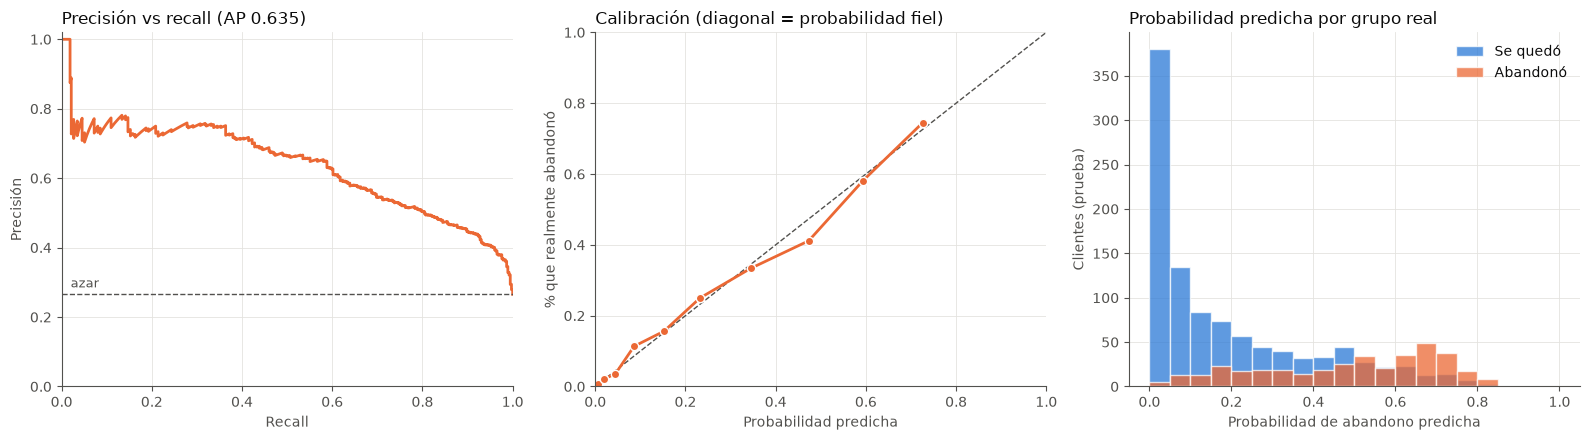

In [3]:
proba = p_test["logistic"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
prec, rec, _ = precision_recall_curve(y_test, proba)
ax = axes[0]
ax.plot(rec, prec, color=CHURN, lw=2)
ax.axhline(y_test.mean(), color=MUTED, ls="--", lw=1)
ax.text(0.02, y_test.mean() + 0.02, "azar", color=MUTED, fontsize=9)
ax.set(xlabel="Recall", ylabel="Precisión", xlim=(0, 1), ylim=(0, 1.02))
ax.set_title(f"Precisión vs recall (AP {average_precision_score(y_test, proba):.3f})", loc="left")
frac, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
ax = axes[1]
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
ax.plot(mean_pred, frac, color=CHURN, lw=2, marker="o", markersize=6, markeredgecolor="white")
ax.set(xlabel="Probabilidad predicha", ylabel="% que realmente abandonó", xlim=(0, 1), ylim=(0, 1))
ax.set_title("Calibración (diagonal = probabilidad fiel)", loc="left")
ax = axes[2]
bins = np.linspace(0, 1, 21)
ax.hist(proba[y_test == 0], bins=bins, color=STAY, alpha=0.75, label="Se quedó", edgecolor="white")
ax.hist(proba[y_test == 1], bins=bins, color=CHURN, alpha=0.75, label="Abandonó", edgecolor="white")
ax.set(xlabel="Probabilidad de abandono predicha", ylabel="Clientes (prueba)")
ax.set_title("Probabilidad predicha por grupo real", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
style.save(fig, paths.figure("modelos", "logistic_evaluacion.png"))

### Regresión logística: peso de cada variable
Coeficientes en log-odds (numéricas por +1 desviación estándar). Es la explicación que la red no ofrece.

,internet_service_fiber_optic,total_charges,contract_month_to_month,paperless_billing,multiple_lines,streaming_movies,streaming_tv,senior_citizen,payment_method_electronic_check,partner,...,contract_one_year,monthly_charges,payment_method_bank_transfer_automatic,payment_method_credit_card_automatic,tech_support,online_security,phone_service,contract_two_year,tenure,internet_service_no
coef,0.772,0.524,0.442,0.372,0.328,0.309,0.308,0.145,0.100,0.02,...,-0.258,-0.261,-0.289,-0.319,-0.329,-0.379,-0.389,-0.908,-1.248,-1.257
odds_ratio,2.165,1.689,1.556,1.450,1.388,1.361,1.361,1.156,1.105,1.02,...,0.773,0.770,0.749,0.727,0.719,0.685,0.678,0.403,0.287,0.284


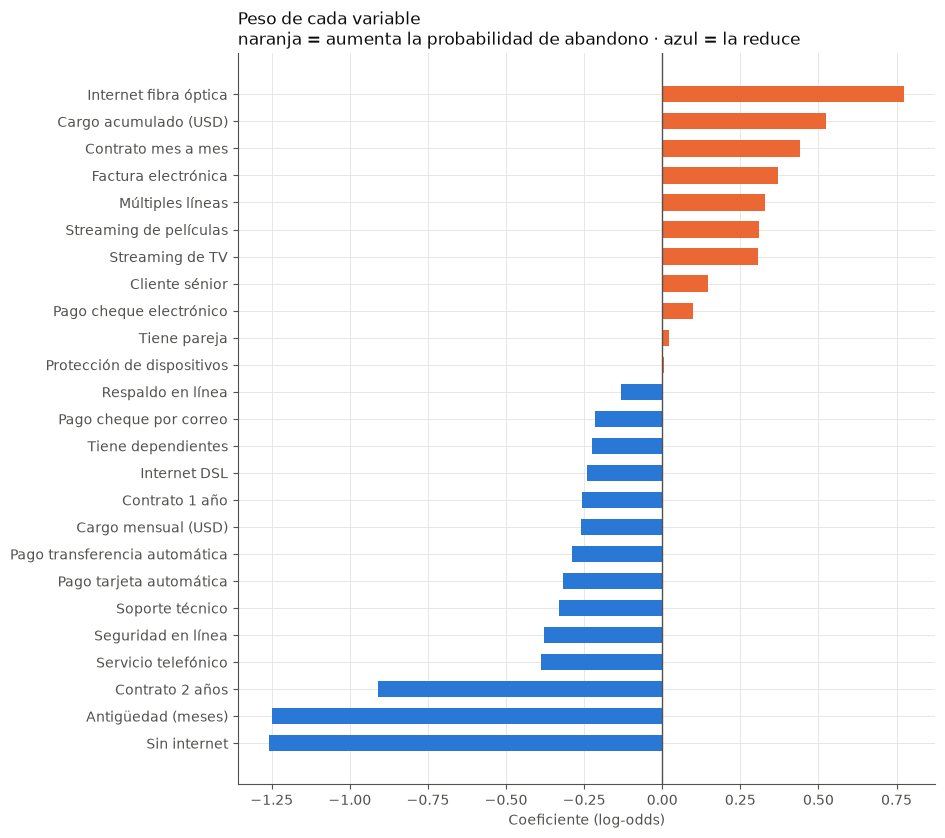

In [4]:
names = logistic.named_steps["scale"].get_feature_names_out()
coef = pd.Series(logistic.named_steps["logreg"].coef_[0], index=names).sort_values()
fig, ax = plt.subplots(figsize=(9, 0.32 * len(coef) + 1.5))
ax.barh([LABELS[c] for c in coef.index], coef.values, color=[CHURN if c > 0 else STAY for c in coef], height=0.6)
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("Coeficiente (log-odds)")
ax.set_title("Peso de cada variable\nnaranja = aumenta la probabilidad de abandono · azul = la reduce", loc="left")
style.save(fig, paths.figure("modelos", "logistic_coeficientes.png"))
pd.DataFrame({"coef": coef, "odds_ratio": np.exp(coef)}).iloc[::-1].round(3).T

### Red neuronal: curva de entrenamiento
El error de validación toca su mínimo pronto y luego sube mientras el de entrenamiento sigue bajando:
la red empieza a memorizar. El early stopping se queda con los pesos de la mejor época.

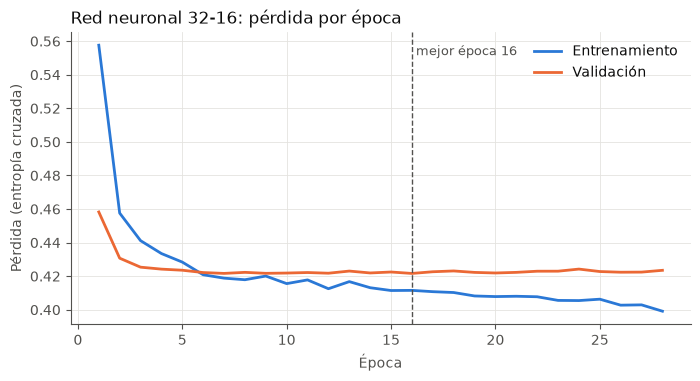

In [5]:
hist = pd.read_csv(paths.TABLES / "neural_training_history.csv")
best = int(hist.val_loss.idxmin())
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(hist.epoch, hist.loss, color=STAY, lw=2, label="Entrenamiento")
ax.plot(hist.epoch, hist.val_loss, color=CHURN, lw=2, label="Validación")
ax.axvline(hist.epoch[best], color=MUTED, ls="--", lw=1)
ax.text(hist.epoch[best], hist.loss.max(), f" mejor época {hist.epoch[best]}", color=MUTED, fontsize=9, va="top")
ax.set(xlabel="Época", ylabel="Pérdida (entropía cruzada)")
ax.set_title("Red neuronal 32-16: pérdida por época", loc="left")
ax.legend(frameon=False)
style.save(fig, paths.figure("modelos", "neural_entrenamiento.png"))

## 2. Del modelo a la decisión: umbral por costo
Contactar conviene cuando el costo esperado de no hacerlo supera al de hacerlo:
p × 120 > (1 − p) × 15 ⇒ p > 15 / 135 = **0,111** (umbral teórico).

En la práctica se busca el umbral de costo mínimo **sin mirar el test**: la logística con predicciones
fuera de pliegue (validación cruzada 5 folds sobre los 5.634 de desarrollo) y la red sobre su conjunto de
validación. Supuesto: contactar a quien sí se iba cuesta 0 adicional (el enunciado no le asigna costo).

In [6]:
THEORETICAL_CUT = FALSE_POSITIVE_COST / (FALSE_NEGATIVE_COST + FALSE_POSITIVE_COST)


def choose_cut(y_true, score) -> float:
    """Umbral de costo mínimo. Empate: el que contacta menos."""
    fpr, tpr, cuts = roc_curve(y_true, score, drop_intermediate=False)
    false_negatives = np.rint((1 - tpr) * y_true.sum()).astype(int)
    false_positives = np.rint(fpr * (len(y_true) - y_true.sum())).astype(int)
    costs = FALSE_NEGATIVE_COST * false_negatives + FALSE_POSITIVE_COST * false_positives
    return float(cuts[np.argmin(costs)])   # cortes en orden descendente


def evaluate(y_true, score, cut) -> dict:
    tn, fp, fn, tp = confusion_matrix(y_true, score >= cut, labels=[0, 1]).ravel()
    return {
        "threshold": cut, "contacts": tp + fp, "true_positives": tp, "false_positives": fp,
        "false_negatives": fn, "true_negatives": tn, "recall": tp / (tp + fn),
        "precision": tp / (tp + fp) if tp + fp else 0.0, "accuracy": (tp + tn) / len(y_true),
        "cost_usd": FALSE_NEGATIVE_COST * fn + FALSE_POSITIVE_COST * fp,
    }


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
selection = {
    "logistic": (y_dev, cross_val_predict(clone(logistic), X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]),
    "neural": (y_val, predict(neural, X_val)),
}
cut = {m: choose_cut(*selection[m]) for m in NAME}
rows = []
for m in NAME:
    for policy, c in (("baseline", 0.5), ("theoretical", THEORETICAL_CUT), ("validation", cut[m])):
        rows.append({"model": m, "policy": policy, "selection_n": len(selection[m][0]),
                     "selection_cost_usd": evaluate(*selection[m], c)["cost_usd"], **evaluate(y_test, p_test[m], c)})
report = pd.DataFrame(rows)
report.to_csv(paths.table("churn_threshold_comparison.csv"), index=False)
nobody = FALSE_NEGATIVE_COST * int(y_test.sum())
everyone = FALSE_POSITIVE_COST * int((y_test == 0).sum())
print(f"Referencias en prueba: no contactar a nadie USD {nobody:,} · contactar a todos USD {everyone:,}")
report.round(4)

Referencias en prueba: no contactar a nadie USD 44,880 · contactar a todos USD 15,525


,model,policy,selection_n,selection_cost_usd,threshold,contacts,true_positives,false_positives,false_negatives,true_negatives,recall,precision,accuracy,cost_usd
0,logistic,baseline,5634,88035,0.5000,316,206,110,168,925,0.5508,0.6519,0.8027,21810
1,logistic,theoretical,5634,42225,0.1111,848,349,499,25,536,0.9332,0.4116,0.6281,10485
2,logistic,validation,5634,40875,0.1341,801,346,455,28,580,0.9251,0.4320,0.6572,10185
3,neural,baseline,1127,17820,0.5000,286,186,100,188,935,0.4973,0.6503,0.7956,24060
4,neural,theoretical,1127,9300,0.1111,855,351,504,23,531,0.9385,0.4105,0.6260,10320
5,neural,validation,1127,8310,0.0658,963,362,601,12,434,0.9679,0.3759,0.5649,10455


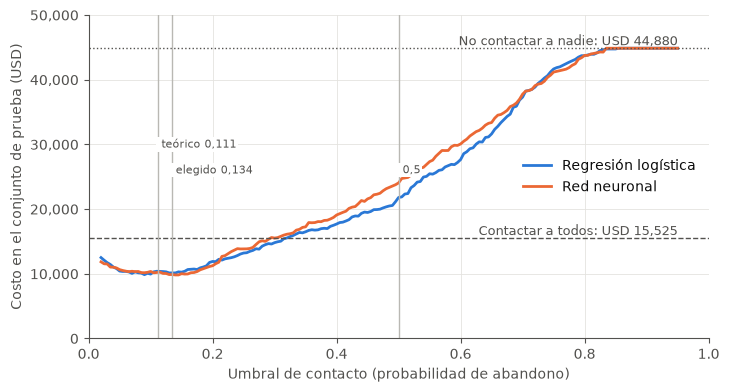

In [7]:
cuts = np.linspace(0.02, 0.95, 187)
fig, ax = plt.subplots(figsize=(8, 4.2))
for m, color in (("logistic", STAY), ("neural", CHURN)):
    ax.plot(cuts, [evaluate(y_test, p_test[m], c)["cost_usd"] for c in cuts], color=color, lw=2, label=NAME[m])
for value, text, ls in ((nobody, "No contactar a nadie", ":"), (everyone, "Contactar a todos", "--")):
    ax.axhline(value, color=MUTED, ls=ls, lw=1)
    ax.text(0.95, value, f"{text}: USD {value:,}", ha="right", va="bottom", fontsize=9, color=MUTED)
for c, text, height in ((THEORETICAL_CUT, " teórico 0,111", 30000),
                        (cut["logistic"], f" elegido {cut['logistic']:.3f}".replace(".", ","), 26000), (0.5, " 0,5", 26000)):
    ax.axvline(c, color="#b9b8b3", lw=1)
    ax.text(c, height, text, ha="left", va="center", fontsize=8, color=MUTED,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.set(xlabel="Umbral de contacto (probabilidad de abandono)", ylabel="Costo en el conjunto de prueba (USD)",
       xlim=(0, 1), ylim=(0, 50000))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(frameon=False, loc="center right")
style.save(fig, paths.figure("modelos", "costo_umbral.png"))

**¿El modelo con mejores métricas es el más conveniente?** Con 0,5 la logística tiene la mayor exactitud
(80 %) pero cuesta más que contactar a todos. Con el umbral de costo la exactitud baja a ~66 % y el
costo cae a menos de la mitad: un falso negativo cuesta 8 veces más que un falso positivo.

## 3. ¿La diferencia entre modelos es real? Bootstrap pareado
1.000 remuestreos del conjunto de prueba; en cada uno se compara a ambos modelos sobre los mismos
clientes. Si el intervalo del 95 % incluye el 0, la diferencia no es concluyente.

In [8]:
rng = np.random.default_rng(SEED)
yt = y_test.to_numpy()
draws = {"costo LR − red (umbrales elegidos)": [], "AUC LR − red": [], "AUC-PR LR − red": []}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    draws["costo LR − red (umbrales elegidos)"].append(
        evaluate(yt[i], p_test["logistic"][i], cut["logistic"])["cost_usd"]
        - evaluate(yt[i], p_test["neural"][i], cut["neural"])["cost_usd"])
    draws["AUC LR − red"].append(roc_auc_score(yt[i], p_test["logistic"][i]) - roc_auc_score(yt[i], p_test["neural"][i]))
    draws["AUC-PR LR − red"].append(average_precision_score(yt[i], p_test["logistic"][i])
                                    - average_precision_score(yt[i], p_test["neural"][i]))
boot = pd.DataFrame({k: {"media": np.mean(v), "IC95 bajo": np.percentile(v, 2.5), "IC95 alto": np.percentile(v, 97.5)}
                     for k, v in draws.items()}).T
boot["concluyente"] = (boot["IC95 bajo"] > 0) | (boot["IC95 alto"] < 0)
boot.to_csv(paths.table("bootstrap_lr_vs_nn.csv"))
boot.round(4)

,media,IC95 bajo,IC95 alto,concluyente
costo LR − red (umbrales elegidos),-288.4500,-1290.0000,765.0000,False
AUC LR − red,0.0063,0.0006,0.0119,True
AUC-PR LR − red,0.0187,0.0041,0.0342,True


La logística ordena algo mejor (AUC), pero en costo ambos modelos empatan.

**Comparación justa del umbral de la red.** La red eligió su umbral sobre 1.127 clientes de validación
(los mismos del early stopping); la logística, sobre 5.634 fuera de pliegue. Se repite la elección para
la red con la misma validación cruzada de 5 folds que la logística (5 redes nuevas).

In [9]:
keras.utils.set_random_seed(SEED)
oof = np.zeros(len(X_dev))
for train_idx, val_idx in cv.split(X_dev, y_dev):
    a, b, ya, yb = split_validation(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
    model = build_model(a.to_numpy(np.float32))
    fit(model, a.to_numpy(np.float32), ya.to_numpy(), b.to_numpy(np.float32), yb.to_numpy())
    oof[val_idx] = predict(model, X_dev.iloc[val_idx])
nn_cv_cut = choose_cut(y_dev, oof)
print(f"Red con umbral elegido por CV fuera de pliegue: {nn_cv_cut:.4f}")
pd.DataFrame([evaluate(y_test, p_test["neural"], nn_cv_cut)]).round(4)

Red con umbral elegido por CV fuera de pliegue: 0.0839


,threshold,contacts,true_positives,false_positives,false_negatives,true_negatives,recall,precision,accuracy,cost_usd
0,0.0839,912,358,554,16,481,0.9572,0.3925,0.5955,10230


## 4. ¿Por qué la red no supera a la logística?

### 4.1 Más capas no ayudan: 32-16 frente a 64-32-16
Cada arquitectura se entrena con 5 semillas sobre la misma partición. Además de AUC se mide el costo
en prueba con el umbral elegido en validación.

In [10]:
ARCHITECTURES = {"32-16": (32, 16), "64-32-16": (64, 32, 16)}
x_train, x_val = X_train.to_numpy(np.float32), X_val.to_numpy(np.float32)
rows = []
for name, units in ARCHITECTURES.items():
    for seed in (0, 1, 2, 3, 42):
        keras.utils.set_random_seed(seed)
        model = build_model(x_train, units)
        history = fit(model, x_train, y_train.to_numpy(), x_val, y_val.to_numpy())
        p = {"train": predict(model, x_train), "val": predict(model, x_val), "test": predict(model, X_test)}
        c = choose_cut(y_val, p["val"])
        rows.append({
            "arquitectura": name, "seed": seed,
            "parametros": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
            "mejor_epoca": int(np.argmin(history["val_loss"])) + 1,
            "auc_train": roc_auc_score(y_train, p["train"]), "auc_val": roc_auc_score(y_val, p["val"]),
            "auc_test": roc_auc_score(y_test, p["test"]),
            "logloss_val": log_loss(y_val, p["val"]), "logloss_test": log_loss(y_test, p["test"]),
            "umbral_validacion": c, "costo_test_usd": evaluate(y_test, p["test"], c)["cost_usd"],
        })
arch = pd.DataFrame(rows)
arch["brecha_auc"] = arch.auc_train - arch.auc_test
arch.to_csv(paths.table("arquitecturas.csv"), index=False)
arch_summary = arch.drop(columns="seed").groupby("arquitectura").agg(["mean", "std"]).round(4)
arch_summary.to_csv(paths.table("arquitecturas_resumen.csv"))
arch_summary

parametros      mejor_epoca          auc_train         auc_val         auc_test         logloss_val         logloss_test         umbral_validacion         costo_test_usd           brecha_auc        
                   mean  std        mean      std      mean     std    mean     std     mean     std        mean     std         mean     std              mean     std           mean       std       mean     std
arquitectura                                                                                                                                                                                                       
32-16            1377.0  0.0        17.0  11.2472    0.8601  0.0078  0.8440  0.0022   0.8377  0.0034      0.4184  0.0019       0.4252  0.0036            0.0816  0.0364        10626.0  102.0662     0.0224  0.0060
64-32-16         4289.0  0.0         8.0   2.4495    0.8621  0.0050  0.8442  0.0034   0.8358  0.0019      0.4176  0.0028       0.4278  0.0026            0.0959  0.0364        10716.0  236.3631     0.0263  0.0055

La red de tres capas tiene el triple de parámetros, empata en validación, rinde algo peor en prueba y
deja de mejorar antes (memoriza antes). Con ~4.500 clientes de entrenamiento, más capas agregan ruido.

### 4.2 La señal es casi aditiva
Si existieran interacciones importantes entre variables, una logística con todas las interacciones de
pares (325 variables, regularizada) debería superar a la simple. No lo hace.

In [11]:
interactions = Pipeline([
    ("s", ColumnTransformer([("num", StandardScaler(), NUMERIC)], remainder="passthrough")),
    ("poly", PolynomialFeatures(2, interaction_only=True, include_bias=False)),
    ("sc", StandardScaler()),
    ("lr", LogisticRegression(max_iter=5000, C=0.05)),
])
oof_inter = cross_val_predict(interactions, X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
p_inter = interactions.fit(X_dev, y_dev).predict_proba(X_test)[:, 1]
pd.DataFrame({
    "AUC fuera de pliegue": [roc_auc_score(y_dev, selection["logistic"][1]), roc_auc_score(y_dev, oof_inter)],
    "AUC prueba": [roc_auc_score(y_test, p_test["logistic"]), roc_auc_score(y_test, p_inter)],
}, index=["Logística simple", "Logística + interacciones"]).round(4)

,AUC fuera de pliegue,AUC prueba
Logística simple,0.8458,0.8425
Logística + interacciones,0.8383,0.8341


### 4.3 Un segmento que ningún modelo captura
Clientes nuevos de fibra con contrato mes a mes (antigüedad ≤ 15 meses y cargo acumulado ≤ USD 120,
en la práctica clientes de su primer mes). Ambos modelos subestiman su riesgo en ~17-18 puntos: la red
tampoco encuentra esa interacción, así que no hay evidencia de que su flexibilidad aporte aquí.

In [12]:
mask = ((X.internet_service_fiber_optic == 1) & (X.contract_month_to_month == 1)
        & (X.tenure <= 15) & (X.total_charges <= 120)).to_numpy()
pd.DataFrame({
    "clientes": [mask.sum()],
    "abandono real": [y[mask].mean() * 100],
    "logística predice": [logistic.predict_proba(X[mask])[:, 1].mean() * 100],
    "red predice": [predict(neural, X[mask]).mean() * 100],
}).round(2)

,clientes,abandono real,logística predice,red predice
0,238,86.55,69.29,68.290001
